# Task 2 (Level 1 — Basic): K-Nearest Neighbors (KNN) Classifier on Iris

Evaluates `KNeighborsClassifier` across $K \in \{1,3,5,7,9,11,13,15,17,19,21,25,31\}$, comparing `StandardScaler` vs raw unscaled features and uniform vs inverse-distance weighting strictly via 5-fold Stratified Cross-Validation on the 120-row training split.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
metrics = json.loads((ROOT / 'results/metrics/task2_knn_metrics.json').read_text())
cv_df = pd.read_csv(ROOT / 'results/tables/task2_knn_cv_sweep.csv')
print('Selected configuration from 5-fold CV:', metrics['selected_hyperparameters'])
print('Held-out Test Accuracy:', round(metrics['final_scaled_knn_test']['accuracy'], 4))
print('Held-out Test Macro-F1:', round(metrics['final_scaled_knn_test']['f1_macro'], 4))
display(cv_df.sort_values(['cv_f1_macro_mean', 'cv_f1_macro_std'], ascending=[False, True]).head(10))

Selected configuration from 5-fold CV: {'n_neighbors': 3, 'weights': 'uniform', 'scaled': True, 'cv_f1_macro_mean': 0.966536, 'cv_f1_macro_std': 0.018707, 'cv_accuracy_mean': 0.966667}
Held-out Test Accuracy: 0.9333
Held-out Test Macro-F1: 0.9327


,k,scaled,weights,train_acc_mean,cv_acc_mean,cv_acc_std,cv_f1_macro_mean,cv_f1_macro_std
47,17,False,distance,1.000000,0.983333,0.022822,0.983268,0.022911
28,5,False,uniform,0.968750,0.975000,0.022822,0.974902,0.022911
35,19,False,uniform,0.968750,0.975000,0.022822,0.974902,0.022911
41,5,False,distance,1.000000,0.975000,0.022822,0.974902,0.022911
42,7,False,distance,1.000000,0.975000,0.022822,0.974902,0.022911
48,19,False,distance,1.000000,0.975000,0.022822,0.974902,0.022911
33,15,False,uniform,0.970833,0.975000,0.037268,0.974703,0.037804
44,11,False,distance,1.000000,0.975000,0.037268,0.974703,0.037804
46,15,False,distance,1.000000,0.975000,0.037268,0.974703,0.037804
34,17,False,uniform,0.970833,0.966667,0.034861,0.966601,0.034880


## 2.1 Investigating Scaling vs Signal Variance on Iris
On the 120-row training CV, scaled `K=3` achieves `0.9665` Macro-F1 (`0.9596` after removing the 3 exact duplicate rows). On the 30-row test split, two borderline *virginica* flowers with atypical `sepal_width` are misclassified as *versicolor* under isotropic standardization because `StandardScaler` assigns noisy `sepal_width` equal variance weight alongside highly discriminative `petal_length` and `petal_width`.

,precision,recall,f1,support
setosa,1.000000,1.0,1.000000,10.0
versicolor,0.833333,1.0,0.909091,10.0
virginica,1.000000,0.8,0.888889,10.0


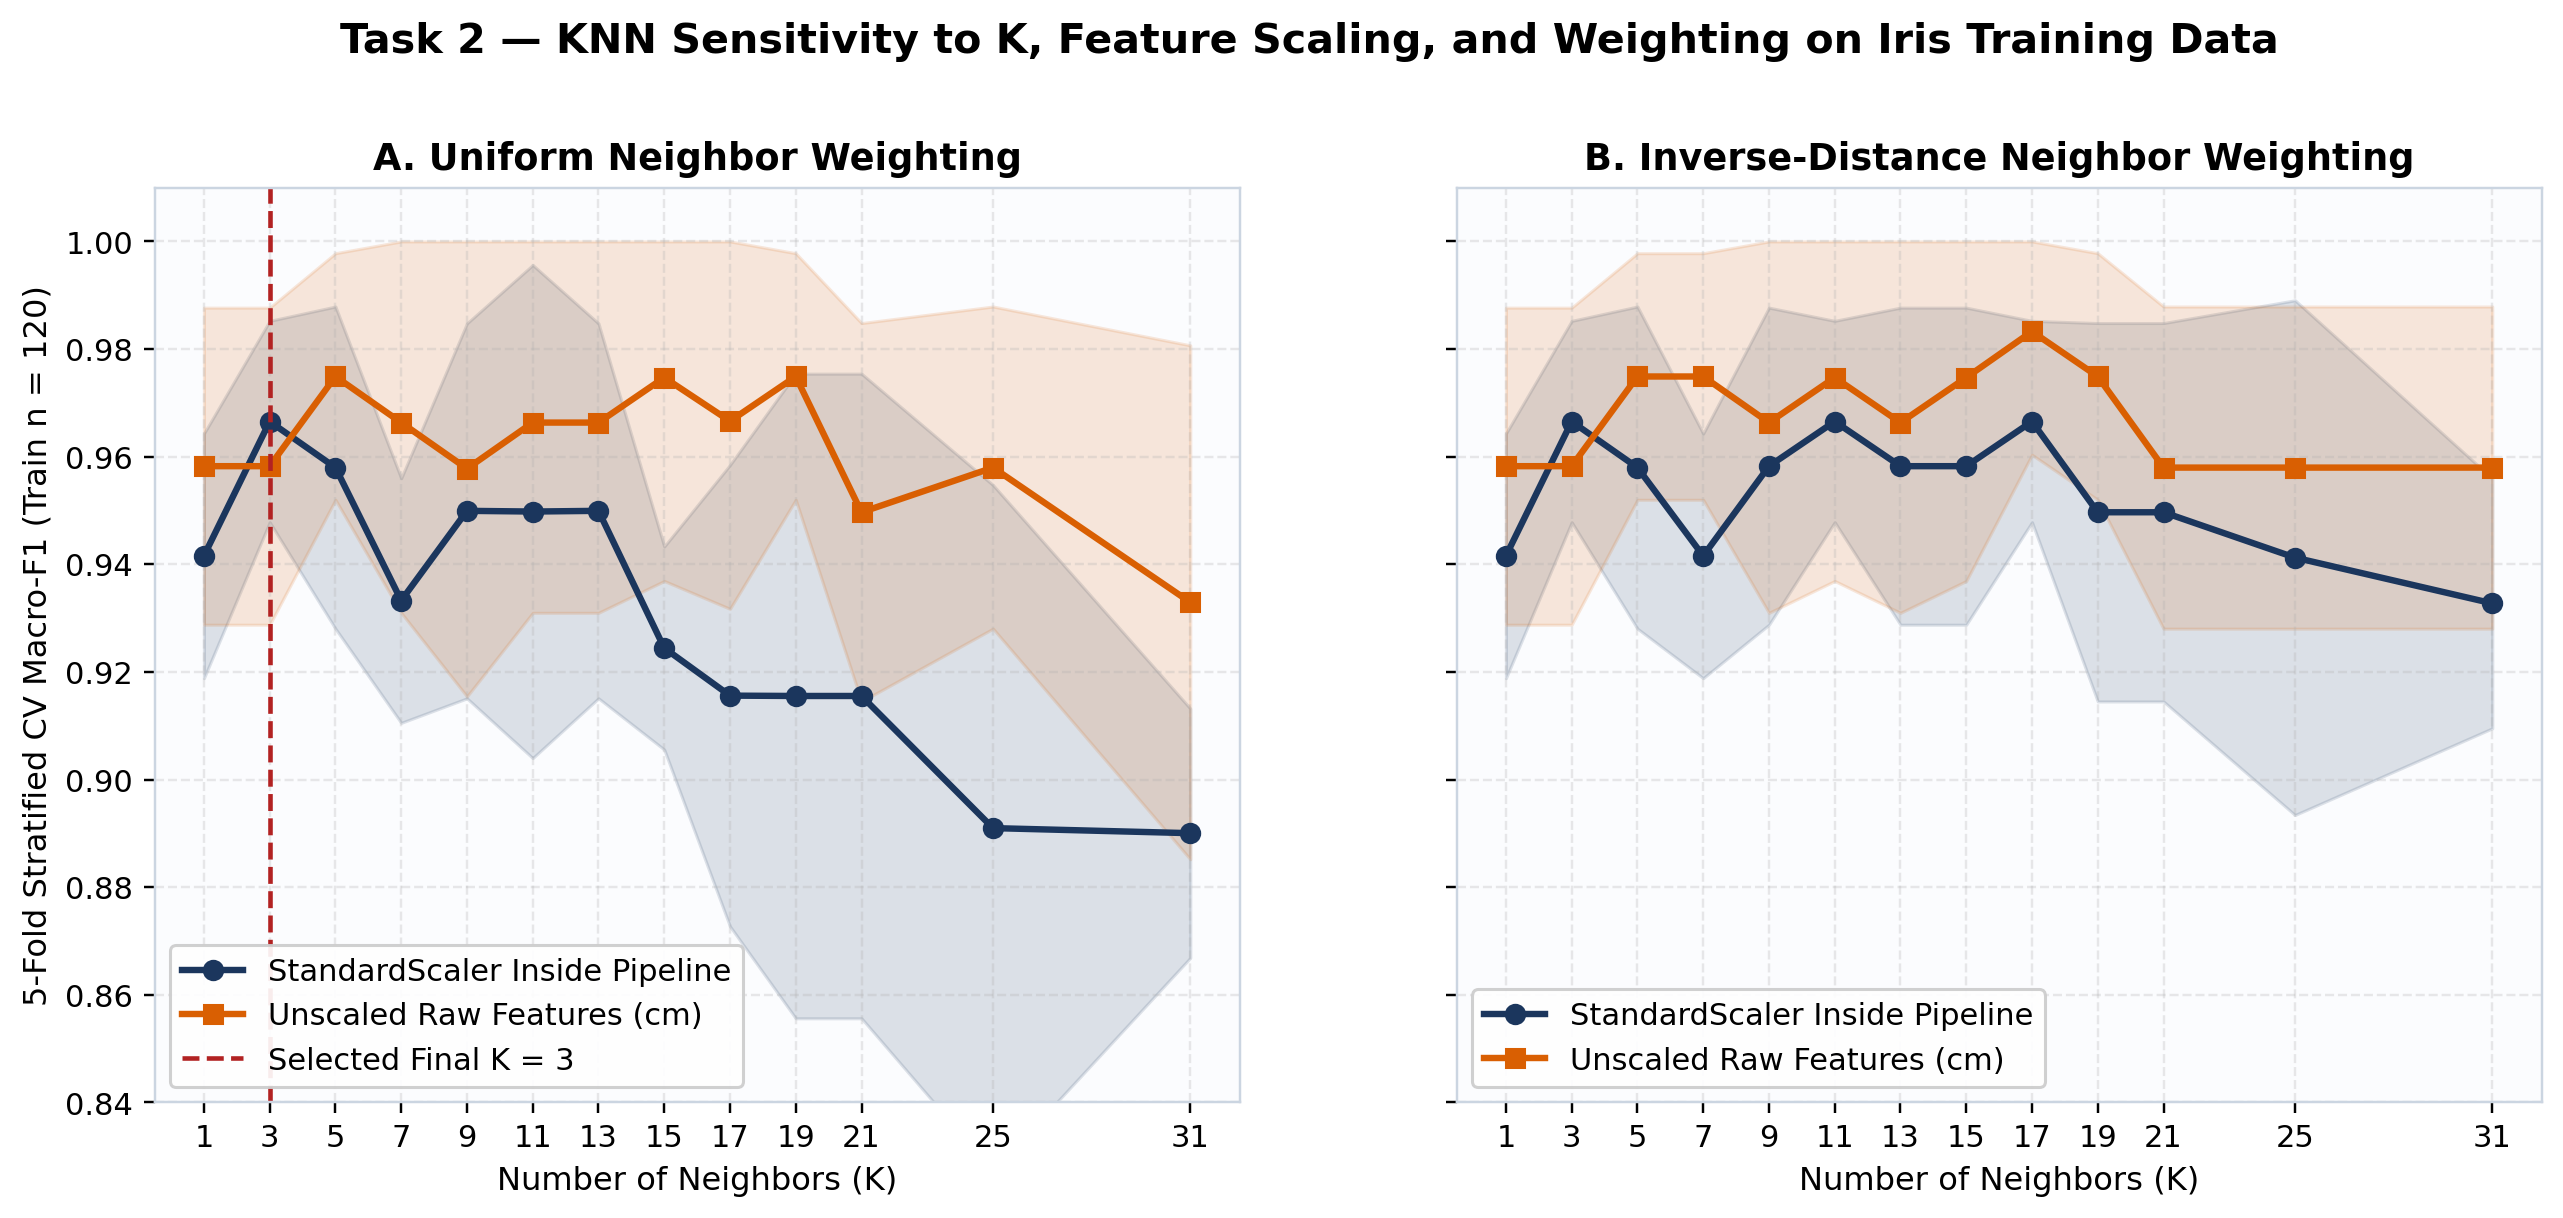

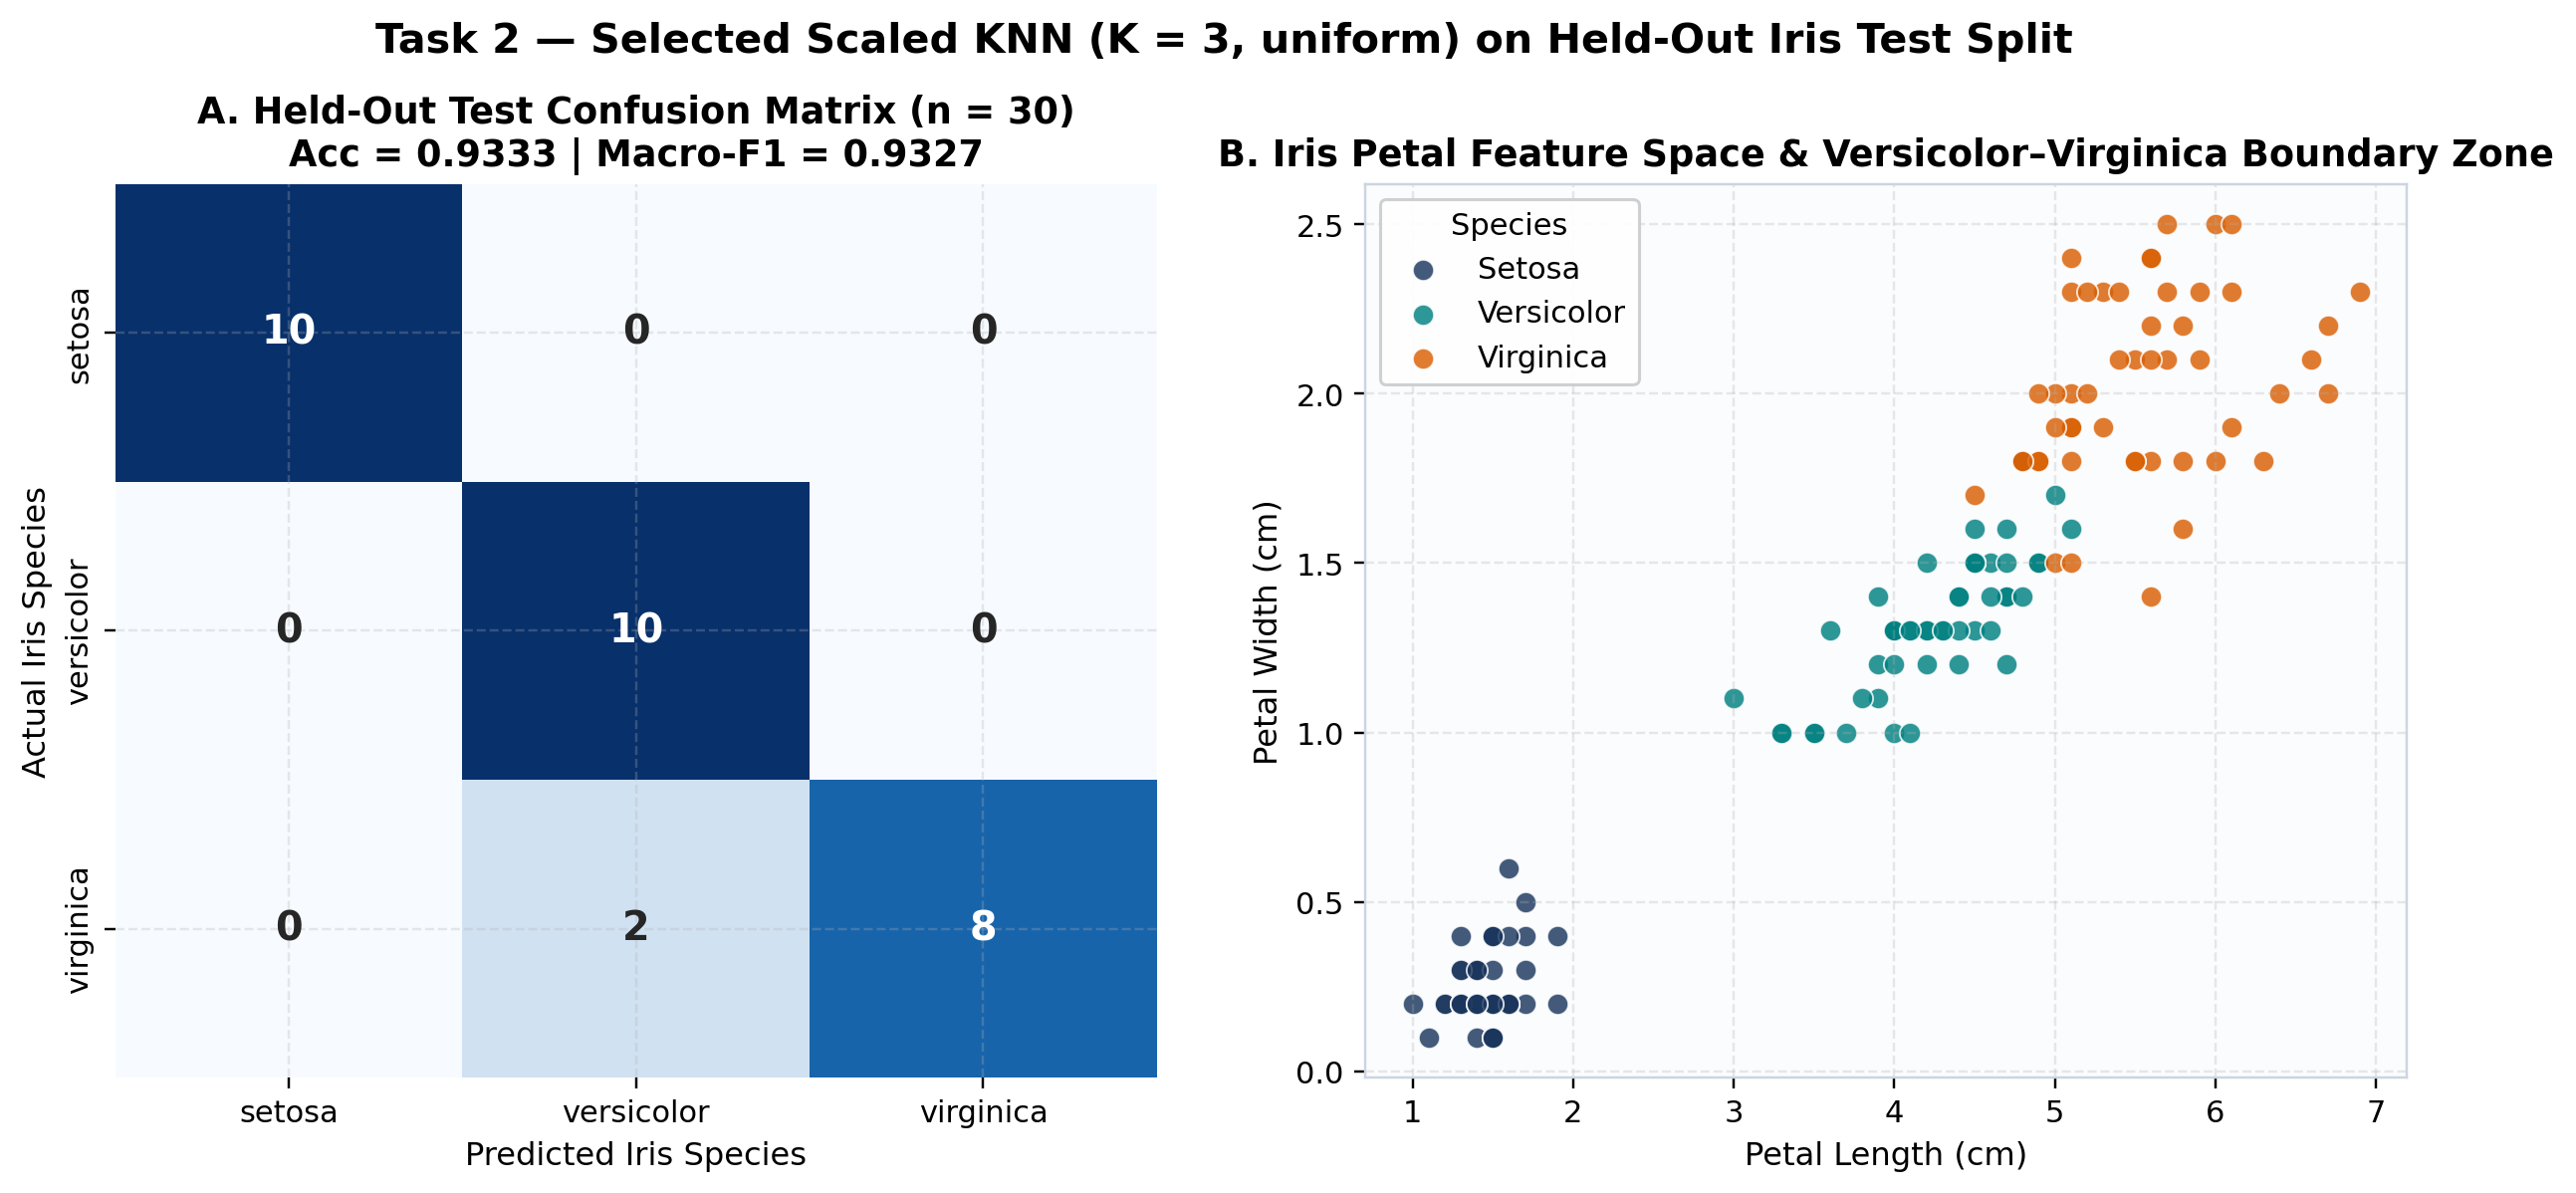

In [2]:
display(pd.DataFrame(metrics['final_scaled_knn_test']['per_class']).T)
display(Image(filename=str(ROOT / 'results/figures/fig03_knn_k_curve_scaled_vs_unscaled.png')))
display(Image(filename=str(ROOT / 'results/figures/fig04_knn_iris_confusion_and_feature_space.png')))